In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pl
import warnings

from xgboost.testing import root_mean_square

warnings.filterwarnings("ignore")

In [2]:
data = pd.read_csv('stud.csv')
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [3]:
data['gender']= data['gender'].map({'male':0, 'female':1})

In [4]:
data['parental_level_of_education'] = data['parental_level_of_education'].replace(
    'some high school',
    'high school'
)

In [5]:
mapping = {
    'high school': 0,
    'some college': 1,
    "associate's degree": 2,
    "bachelor's degree": 3,
    "master's degree": 4
}

data['parental_level_of_education'] = data['parental_level_of_education'].map(mapping)

In [6]:
data['test_preparation_course']=data['test_preparation_course'].map({'none':0,'completed':1})

In [7]:
data.duplicated().sum()

np.int64(0)

In [8]:
data[data.duplicated()]

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score


In [9]:
print(f"Unique values : \n{data.nunique()}")
print(f"Unique values sum : \n{data.nunique().sum()}")

Unique values : 
gender                          2
race_ethnicity                  5
parental_level_of_education     5
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64
Unique values sum : 
246


In [10]:
data.describe()

,gender,parental_level_of_education,test_preparation_course,math_score,reading_score,writing_score
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,0.518000,1.260000,0.358000,66.08900,69.169000,68.054000
std,0.499926,1.238521,0.479652,15.16308,14.600192,15.195657
min,0.000000,0.000000,0.000000,0.00000,17.000000,10.000000
25%,0.000000,0.000000,0.000000,57.00000,59.000000,57.750000
50%,1.000000,1.000000,0.000000,66.00000,70.000000,69.000000
75%,1.000000,2.000000,1.000000,77.00000,79.000000,79.000000
max,1.000000,4.000000,1.000000,100.00000,100.000000,100.000000


In [11]:
data = data.drop(columns=['race_ethnicity','lunch'])

<Figure size 640x480 with 0 Axes>

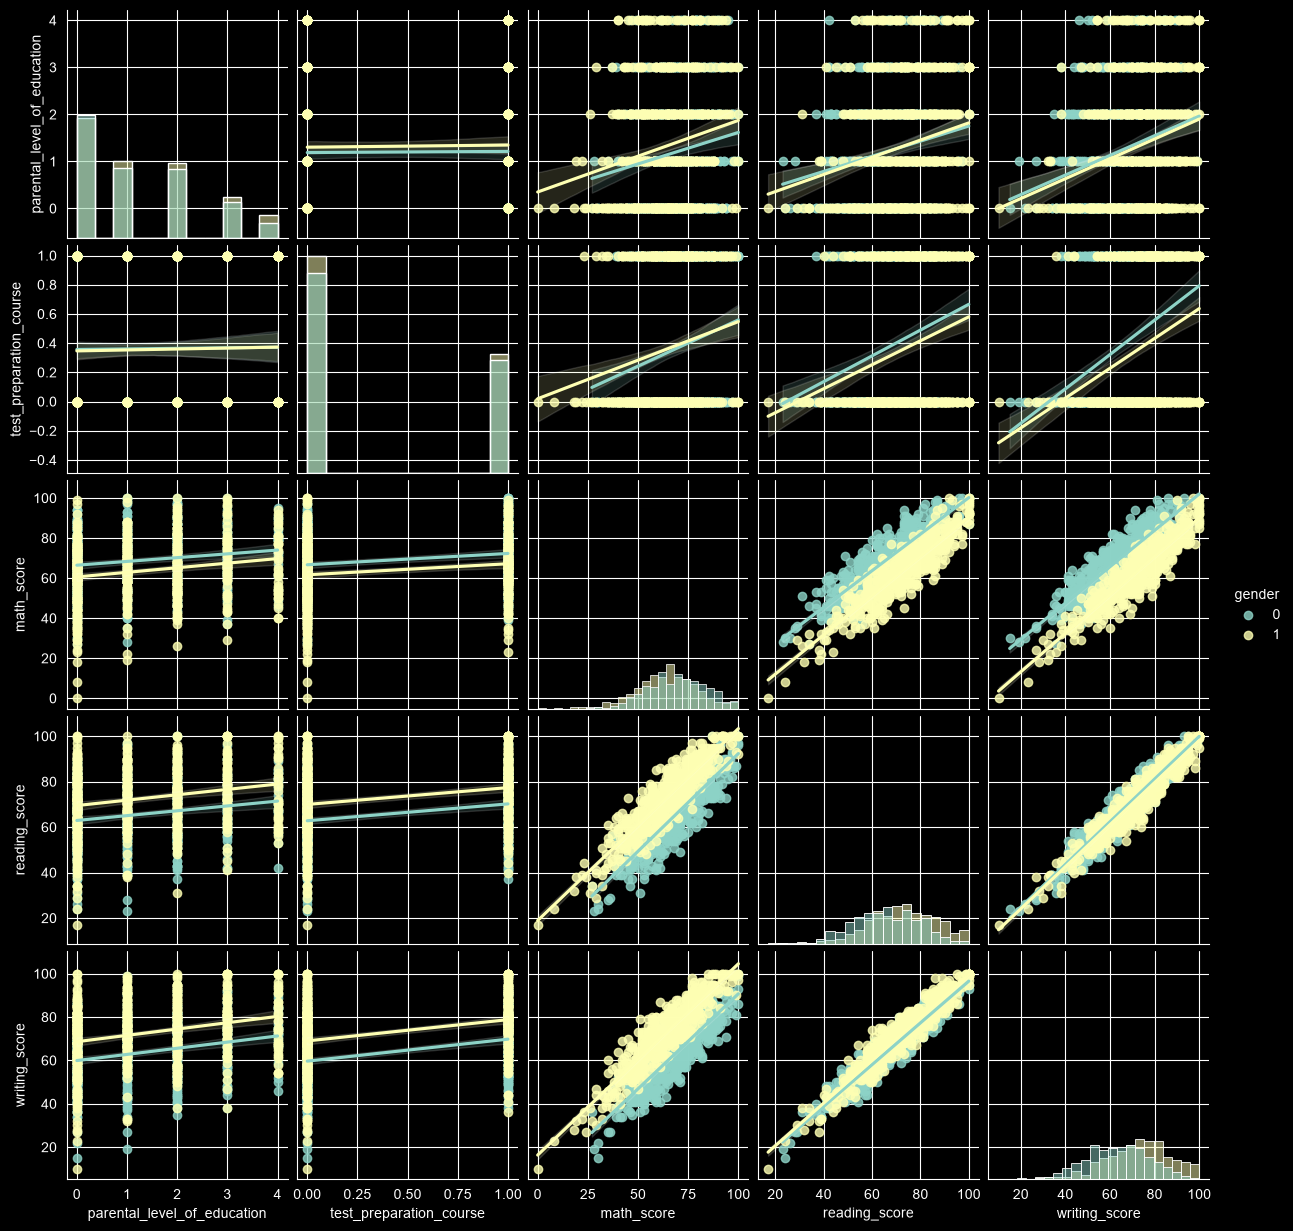

In [12]:
pl.figure()
sns.pairplot(data, hue='gender' ,kind='reg',diag_kind='hist')

In [13]:
Q1 = data.quantile(.25)
Q3 = data.quantile(.75)
IQR = Q3 - Q1
Upper = Q3+1.5*IQR
Low = Q1-1.5*IQR
is_outlier = (data < Low) | (data > Upper)
clean_data = data[~is_outlier.any(axis=1)]

<Figure size 640x480 with 0 Axes>

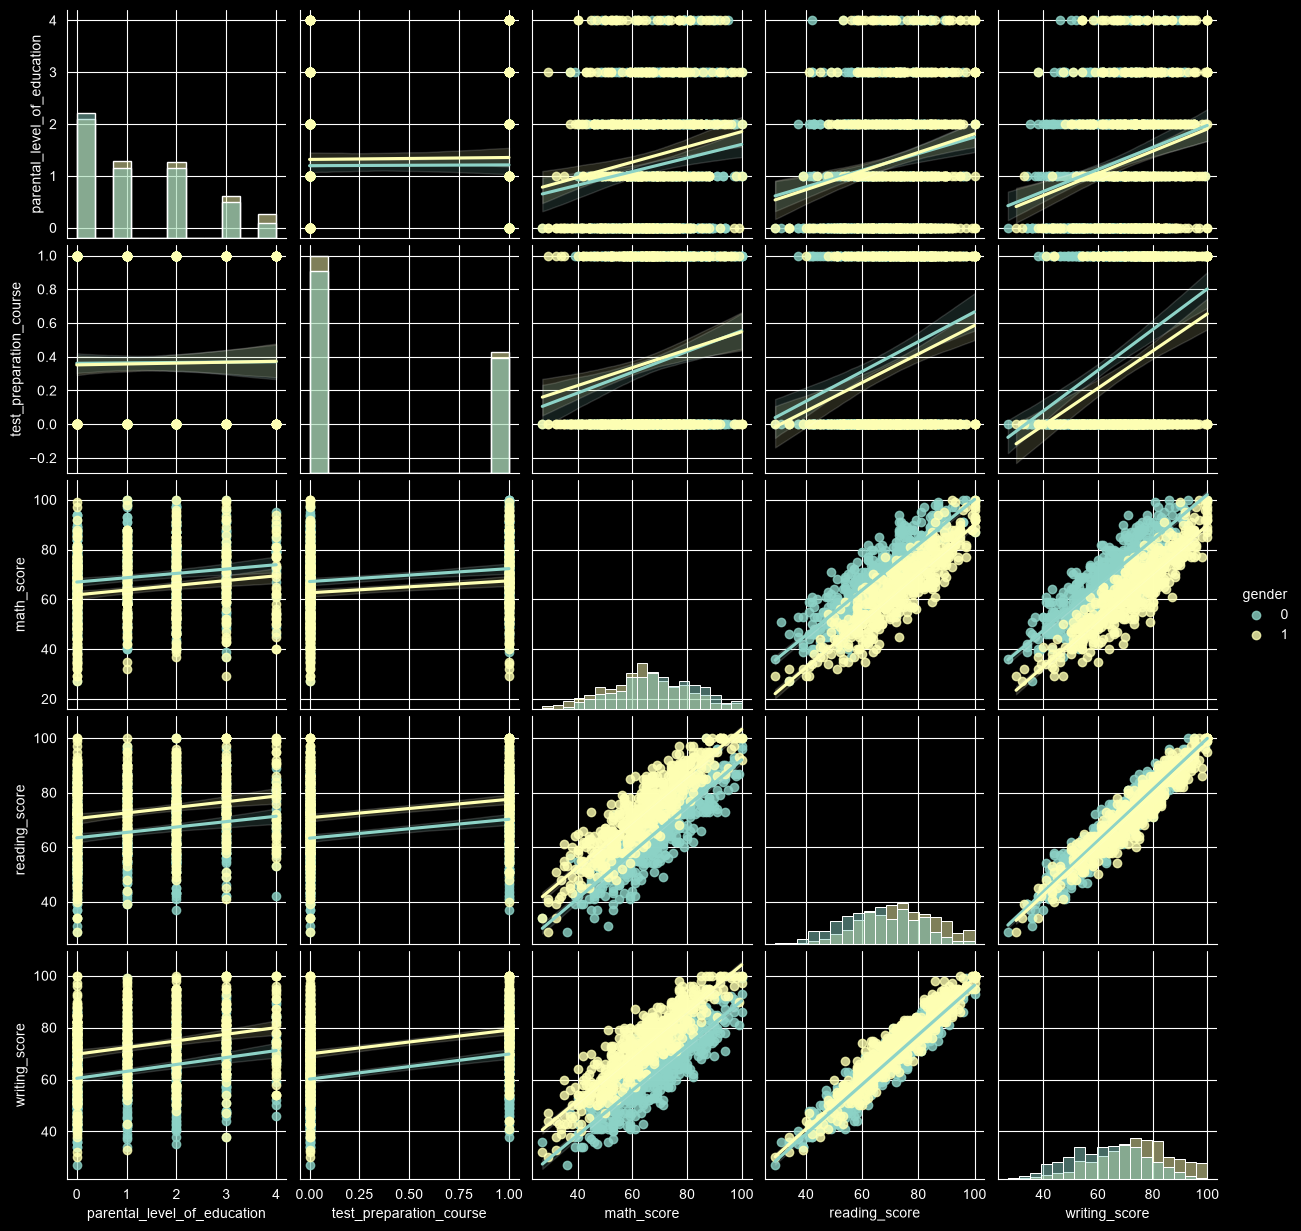

In [14]:
pl.figure()
sns.pairplot(clean_data, hue='gender' ,kind='reg',diag_kind='hist')

In [15]:
clean_data=clean_data.drop(columns=['parental_level_of_education','test_preparation_course'])
clean_data.info()

<class 'pandas.DataFrame'>
Index: 988 entries, 0 to 999
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   gender         988 non-null    int64
 1   math_score     988 non-null    int64
 2   reading_score  988 non-null    int64
 3   writing_score  988 non-null    int64
dtypes: int64(4)
memory usage: 38.6 KB


In [16]:
clean_data['total_score'] = clean_data['math_score'] + clean_data['reading_score'] + clean_data['writing_score']
clean_data['average_score'] = clean_data['total_score']/3

In [17]:
clean_data.info()

<class 'pandas.DataFrame'>
Index: 988 entries, 0 to 999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   gender         988 non-null    int64  
 1   math_score     988 non-null    int64  
 2   reading_score  988 non-null    int64  
 3   writing_score  988 non-null    int64  
 4   total_score    988 non-null    int64  
 5   average_score  988 non-null    float64
dtypes: float64(1), int64(5)
memory usage: 54.0 KB


<Axes: xlabel='average_score', ylabel='Count'>

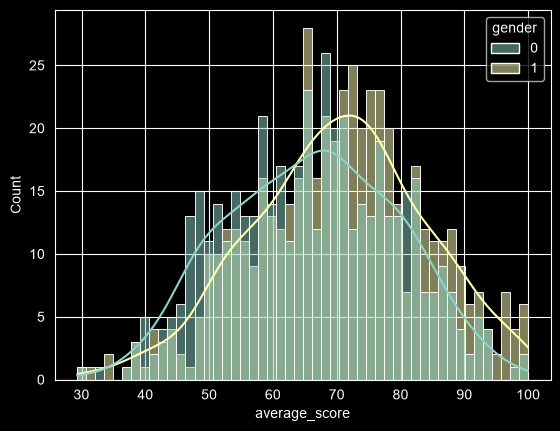

In [18]:
pl.figure()
sns.histplot(data=clean_data,x=clean_data['average_score'] ,bins=50,hue='gender',kde=True)

In [19]:
features = ['reading_score','writing_score']

In [27]:
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor
from sklearn.svm import SVR
from sklearn. linear_model import LinearRegression, Ridge,Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import warnings

In [35]:
x = data.drop(columns=['math_score'])
y = data['math_score']

In [36]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [40]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(true, predicted)

    return mae, mse, rmse, r2

In [48]:
models = {
    "Linear Regression" : LinearRegression(),
    "Ridge Regression" : Ridge(),
    "Lasso Regression" : Lasso(),
    "Decision Tree Regression" : DecisionTreeRegressor(),
    "Random Forest Regression" : RandomForestRegressor(),
    "AdaBoost Regression" : AdaBoostRegressor(),
    "CatBoost Regression" : CatBoostRegressor(verbose=False),
    "XGBoost Regression" : XGBRegressor(),
    "KNN Regression" : KNeighborsRegressor(),
}
model_List = []
r2_list = []
for i in range(len(list(models))):

    model = list(models.values())[i]

    model.fit(x_train, y_train)

    y_train_pred = model.predict(x_train)
    y_test_pred = model.predict(x_test)

    # Evaluate model
    model_train_mae, model_train_mse, model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)

    model_test_mae, model_test_mse, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)

    print(list(models.keys())[i])

    model_List.append(list(models.keys())[i])
    r2_list.append(model_test_r2)
    print("Model performance for training")
    print(f"RMSE:{model_train_rmse:.3f}")
    print(f"MSE:{model_train_mse:.3f}")
    print(f"MAE:{model_train_mae:.3f}")
    print(f"R2:{model_train_r2:.3f}")
    print("Model performance for testing")
    print(f"RMSE:{model_test_rmse:.3f}")
    print(f"MSE:{model_test_mse:.3f}")
    print(f"MAE:{model_test_mae:.3f}")
    print(f"R2:{model_test_r2:.3f}")

Linear Regression
Model performance for training
RMSE:5.872
MSE:34.478
MAE:4.708
R2:0.847
Model performance for testing
RMSE:5.501
MSE:30.261
MAE:4.371
R2:0.876
Ridge Regression
Model performance for training
RMSE:5.872
MSE:34.479
MAE:4.707
R2:0.847
Model performance for testing
RMSE:5.504
MSE:30.297
MAE:4.372
R2:0.875
Lasso Regression
Model performance for training
RMSE:6.476
MSE:41.934
MAE:5.113
R2:0.814
Model performance for testing
RMSE:6.363
MSE:40.490
MAE:5.017
R2:0.834
Decision Tree Regression
Model performance for training
RMSE:1.245
MSE:1.549
MAE:0.258
R2:0.993
Model performance for testing
RMSE:8.267
MSE:68.351
MAE:6.673
R2:0.719
Random Forest Regression
Model performance for training
RMSE:2.600
MSE:6.758
MAE:2.003
R2:0.970
Model performance for testing
RMSE:6.413
MSE:41.126
MAE:4.965
R2:0.831
AdaBoost Regression
Model performance for training
RMSE:6.215
MSE:38.630
MAE:5.094
R2:0.829
Model performance for testing
RMSE:6.351
MSE:40.340
MAE:4.914
R2:0.834
CatBoost Regression
Mo

In [50]:
pd.DataFrame(list(zip(model_List,r2_list)),columns=['Model','R2']).sort_values(by='R2',ascending=False)

,Model,R2
0,Linear Regression,0.875642
1,Ridge Regression,0.875496
6,CatBoost Regression,0.847498
5,AdaBoost Regression,0.834223
2,Lasso Regression,0.833605
4,Random Forest Regression,0.830994
7,XGBoost Regression,0.791708
3,Decision Tree Regression,0.719110
8,KNN Regression,0.679397
